### 서울시 자치구별 지가와 요양시설 잔여정원 상관관계

본 분석은 '초고령 사회, 서울의 의료·돌봄 인프라는 어디에 더 필요한가?'에서 **서울 안에서도 땅값이 비싼 자치구일수록 요양시설에 남는 자리가 적은가**를 확인하기 위해 작성되었다. 한국은행(2026)은 전국 시군구 패널로 '지가가 10% 높을수록 잔여정원 비율이 2.3%p 낮다'고 추정했다(그림 3.2, 별첨 2). 17개 시도 비교(별도 폴더)에서는 이 관계가 서울 한 곳에 크게 기대고 있었으므로, 여기서는 서울 25개 자치구만으로 같은 관계가 다시 나타나는지 본다.

### 1. 분석 기준

- 분석 단위: 서울특별시 25개 자치구
- 지가: 국토교통부 표준지공시지가(2024-01-01 공시 기준), **자치구 안 표준지의 ㎡당 공시지가 단순평균** — 한국은행 별첨 2의 정의(`단위면적(㎡)당 평균 표준지공시지가`, 로그 변환)와 같다.
- 잔여정원 비율: `(입소 정원 − 현원) ÷ 장기요양 1~2등급 인정자 수 × 100` — 한국은행 시군구 분석의 종속변수, 기존 자치구 분석 6절과 같은 정의
  - 시설: 국민건강보험공단 장기요양기관 시설별 현황(2024-07-16), 입소시설 A01~A05
  - 수요: 국민건강보험공단 노인장기요양보험 등급판정 현황(2024-07-31)
- 보조 지표(경로 점검용)
  - 중증 수요 대비 정원: `정원 ÷ 1~2등급 인정자 × 100` — 지가가 공급량 자체를 누르는가
  - 가동률: `현원 ÷ 정원` — 있는 자리가 얼마나 차 있는가
- 통계량: 피어슨 상관(ln 지가), 스피어만 순위상관, 단순회귀 기울기(HC1 강건 표준오차)

시설·등급 원자료는 `서울시 자치구별 75세 이상 인구 대비 요양시설 정원/assets`의 파일을 그대로 읽는다(복사하지 않음). 표준지공시지가 원자료(약 58만 필지, 170MB)는 공공데이터포털에서 내려받아 `assets/`에 캐시하며 git에는 올리지 않는다. 집계 결과는 `outputs/`에 저장한다.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import statsmodels.formula.api as smf
from IPython.display import display, Markdown
from scipy import stats

pd.set_option("display.max_rows", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

plt.rcParams["font.family"] = ["AppleGothic", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

ASSET_DIR = Path("assets")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

GU_ANALYSIS_DIR = Path("..") / "서울시 자치구별 75세 이상 인구 대비 요양시설 정원" / "assets"
FACILITY_FILE = GU_ANALYSIS_DIR / "국민건강보험공단_장기요양기관 시설별 현황_20240716.xlsx"
GRADE_FILE = GU_ANALYSIS_DIR / "국민건강보험공단_노인장기요양보험 등급판정 현황_20240731.csv"

# 공공데이터포털 '국토교통부_표준지공시지가'(15004246)의 2024-01-01 이력 파일
LAND_FILE = ASSET_DIR / "국토교통부_표준지공시지가_20240101.csv"
LAND_URL = (
    "https://www.data.go.kr/cmm/cmm/fileDownload.do"
    "?atchFileId=FILE_000000002945598&fileDetailSn=1&insertDataPrcus=N"
)
RESIDENTIAL_CODES = ["A01", "A02", "A03", "A04", "A05"]

### 2. 자치구별 지가 집계

한국은행 정의대로 표준지의 ㎡당 공시지가를 자치구별로 단순평균한다. 8절의 강건성 점검을 위해 두 가지 대안 지표도 함께 계산한다.

- `중위 지가`: 극단적으로 비싼 도심 표준지에 덜 민감한 중앙값
- `대지 평균 지가`: 지목이 `대`(건축물을 지을 수 있는 땅)인 표준지만의 평균 — 요양시설이 실제로 들어서는 토지에 가깝다.

In [2]:
if not LAND_FILE.exists():
    ASSET_DIR.mkdir(exist_ok=True)
    with requests.get(LAND_URL, stream=True, timeout=600) as response:
        response.raise_for_status()
        with open(LAND_FILE, "wb") as f:
            for chunk in response.iter_content(chunk_size=1 << 20):
                f.write(chunk)

land = pd.read_csv(
    LAND_FILE, encoding="utf-8-sig", usecols=["시도명", "시군구명", "지목", "공시지가"]
)
land = land.loc[land["시도명"].eq("서울특별시")].rename(columns={"시군구명": "자치구"})
assert land["자치구"].nunique() == 25 and (land["공시지가"] > 0).all()

land_by_gu = land.groupby("자치구").agg(
    표준지수=("공시지가", "size"),
    평균_지가=("공시지가", "mean"),
    중위_지가=("공시지가", "median"),
)
land_by_gu["대지_평균_지가"] = land.loc[land["지목"].eq("대")].groupby("자치구")["공시지가"].mean()
land_by_gu = land_by_gu.reset_index()
land_by_gu.to_csv(OUTPUT_DIR / "자치구별_표준지공시지가_2024.csv", index=False, encoding="utf-8-sig")
seoul_land = land["공시지가"].mean()

print(f"서울 표준지 {len(land):,}필지, 서울 평균 ㎡당 {seoul_land:,.0f}원")
land_by_gu.sort_values("평균_지가", ascending=False).style.format({
    "표준지수": "{:,.0f}", "평균_지가": "{:,.0f}", "중위_지가": "{:,.0f}", "대지_평균_지가": "{:,.0f}",
}).hide(axis="index")

서울 표준지 31,044필지, 서울 평균 ㎡당 6,778,948원


자치구,표준지수,평균_지가,중위_지가,대지_평균_지가
강남구,"1,350","16,803,182","12,655,000","17,783,951"
중구,"1,646","13,990,322","8,906,000","14,075,488"
서초구,"1,395","10,643,176","8,611,000","12,452,518"
용산구,"1,220","9,666,904","8,262,000","9,711,612"
종로구,"2,082","9,045,009","5,635,000","9,339,435"
마포구,"1,345","8,676,372","7,437,000","8,768,457"
송파구,"1,076","8,069,890","7,005,500","8,279,389"
성동구,942,"6,484,237","6,006,000","6,453,168"
영등포구,"1,248","5,957,836","4,932,500","5,990,831"
광진구,"1,075","5,778,178","5,126,000","5,861,010"


### 3. 자치구별 잔여정원 비율 집계

기존 자치구 분석과 같은 방식으로 `일반현황`의 소재지(법정동명이 빈 기관은 상세주소로 보완)와 `입소인원`의 정원·현원을 기관코드로 결합해 자치구별로 합친다.

In [3]:
general = pd.read_excel(FACILITY_FILE, sheet_name="일반현황", dtype={"장기요양기관코드": str})
capacity = pd.read_excel(FACILITY_FILE, sheet_name="입소인원", dtype={"장기요양기관코드": str})

region = general["시도 시군구 법정동명"].str.extract(r"^(\S+)\s+(\S+)")
region_fallback = general["기관별 상세주소"].str.extract(r"^(\S+)\s+(\S+)")
general["시도"] = region[0].fillna(region_fallback[0])
general["자치구"] = region[1].fillna(region_fallback[1])

residential = capacity.loc[capacity["기관유형코드"].isin(RESIDENTIAL_CODES)].merge(
    general.loc[general["시도"].eq("서울특별시"), ["장기요양기관코드", "자치구"]],
    on="장기요양기관코드", how="inner", validate="many_to_one",
)
facility_by_gu = residential.groupby("자치구", as_index=False).agg(
    시설수=("장기요양기관코드", "nunique"), 정원=("정원", "sum"), 현원=("현원", "sum")
)

grade_raw = pd.read_csv(GRADE_FILE, encoding="cp949")
grade_raw.columns = [c.strip() for c in grade_raw.columns]
for col in ["시도", "시군구"]:
    grade_raw[col] = grade_raw[col].astype(str).str.strip()
for col in ["1등급", "2등급"]:
    grade_raw[col] = pd.to_numeric(
        grade_raw[col].astype(str).str.replace(",", "", regex=False), errors="coerce"
    )
grade_raw["중증_1_2등급"] = grade_raw["1등급"] + grade_raw["2등급"]
severe_by_gu = (
    grade_raw.loc[grade_raw["시도"].eq("서울")]
    .groupby("시군구", as_index=False)["중증_1_2등급"].sum()
    .rename(columns={"시군구": "자치구"})
)

supply = facility_by_gu.merge(severe_by_gu, on="자치구", how="inner", validate="one_to_one")
supply["잔여정원"] = supply["정원"] - supply["현원"]
supply["잔여정원_비율"] = supply["잔여정원"] / supply["중증_1_2등급"] * 100
supply["중증_대비_정원"] = supply["정원"] / supply["중증_1_2등급"] * 100
supply["가동률"] = supply["현원"] / supply["정원"] * 100
assert len(supply) == 25

seoul_vacancy_ratio = supply["잔여정원"].sum() / supply["중증_1_2등급"].sum() * 100
seoul_bed_ratio = supply["정원"].sum() / supply["중증_1_2등급"].sum() * 100
seoul_occupancy = supply["현원"].sum() / supply["정원"].sum() * 100

### 4. 결합

In [4]:
gu = supply.merge(land_by_gu, on="자치구", how="inner", validate="one_to_one")
assert len(gu) == 25 and not gu.isna().any().any()

for col in ["평균_지가", "중위_지가", "대지_평균_지가"]:
    gu[f"ln_{col}"] = np.log(gu[col])
gu = gu.sort_values("평균_지가", ascending=False).reset_index(drop=True)
gu.to_csv(OUTPUT_DIR / "자치구별_지가_잔여정원.csv", index=False, encoding="utf-8-sig")

display(
    gu[["자치구", "평균_지가", "정원", "현원", "잔여정원", "중증_1_2등급", "잔여정원_비율", "중증_대비_정원", "가동률"]]
    .style.format({
        "평균_지가": "{:,.0f}", "정원": "{:,.0f}", "현원": "{:,.0f}", "잔여정원": "{:,.0f}",
        "중증_1_2등급": "{:,.0f}", "잔여정원_비율": "{:.1f}", "중증_대비_정원": "{:.1f}", "가동률": "{:.1f}",
    })
    .background_gradient(subset=["잔여정원_비율"], cmap="Blues")
    .hide(axis="index")
)

자치구,평균_지가,정원,현원,잔여정원,중증_1_2등급,잔여정원_비율,중증_대비_정원,가동률
강남구,"16,803,182",303,253,50,"1,394",3.6,21.7,83.5
중구,"13,990,322",83,81,2,256,0.8,32.4,97.6
서초구,"10,643,176",322,312,10,923,1.1,34.9,96.9
용산구,"9,666,904",172,171,1,475,0.2,36.2,99.4
종로구,"9,045,009",400,382,18,455,4.0,87.9,95.5
마포구,"8,676,372",380,380,0,697,0.0,54.5,100.0
송파구,"8,069,890",791,754,37,"1,243",3.0,63.6,95.3
성동구,"6,484,237",411,367,44,526,8.4,78.1,89.3
영등포구,"5,957,836",260,249,11,"1,008",1.1,25.8,95.8
광진구,"5,778,178",588,568,20,659,3.0,89.2,96.6


### 5. 상관분석

자치구 사이 지가 차이는 최대 약 5배(강남구 ÷ 도봉구)로 시도보다 작지만, 한국은행과 같이 로그를 취한다. 잔여정원은 자치구별 0~207석으로 작아 몇 명의 입·퇴소에도 비율이 흔들리므로 순위 기반의 스피어만 상관을 함께 본다.

In [5]:
def correlate(data, y, x="ln_평균_지가"):
    pearson = stats.pearsonr(data[x], data[y])
    spearman = stats.spearmanr(data[x], data[y])
    model = smf.ols(f"{y} ~ {x}", data=data).fit(cov_type="HC1")
    return {
        "n": len(data),
        "피어슨_r": pearson.statistic, "피어슨_p": pearson.pvalue,
        "스피어만_rho": spearman.statistic, "스피어만_p": spearman.pvalue,
        "기울기": model.params[x], "기울기_p": model.pvalues[x],
        "지가10%당_변화(%p)": model.params[x] * np.log(1.1),
    }


TARGETS = {
    "잔여정원 비율(%)": "잔여정원_비율",
    "중증 수요 대비 정원(%)": "중증_대비_정원",
    "가동률(%)": "가동률",
}
result = pd.DataFrame(
    [correlate(gu, col) for col in TARGETS.values()], index=list(TARGETS)
).rename_axis("종속변수")
main = result.loc["잔여정원 비율(%)"]
display(result.style.format({
    "n": "{:.0f}", "피어슨_r": "{:.2f}", "피어슨_p": "{:.4f}", "스피어만_rho": "{:.2f}",
    "스피어만_p": "{:.4f}", "기울기": "{:.2f}", "기울기_p": "{:.4f}", "지가10%당_변화(%p)": "{:.2f}",
}))
display(Markdown(
    f"- ln(평균 지가)와 잔여정원 비율의 피어슨 상관: **r = {main['피어슨_r']:.2f}** (p = {main['피어슨_p']:.4f})\n"
    f"- 스피어만 순위상관: **ρ = {main['스피어만_rho']:.2f}** (p = {main['스피어만_p']:.1e})\n"
    f"- 회귀 기울기: 지가가 10% 높은 자치구는 잔여정원 비율이 평균 **{abs(main['지가10%당_변화(%p)']):.2f}%p** 낮다"
))

,n,피어슨_r,피어슨_p,스피어만_rho,스피어만_p,기울기,기울기_p,지가10%당_변화(%p)
종속변수,,,,,,,,
잔여정원 비율(%),25,-0.68,0.0002,-0.79,0.0000,-7.41,0.0001,-0.71
중증 수요 대비 정원(%),25,-0.74,0.0000,-0.78,0.0000,-47.12,0.0000,-4.49
가동률(%),25,0.38,0.0580,0.54,0.0050,4.52,0.2002,0.43


- ln(평균 지가)와 잔여정원 비율의 피어슨 상관: **r = -0.68** (p = 0.0002)
- 스피어만 순위상관: **ρ = -0.79** (p = 3.2e-06)
- 회귀 기울기: 지가가 10% 높은 자치구는 잔여정원 비율이 평균 **0.71%p** 낮다

### 6. 시각화: 지가와 잔여정원 비율

서울 평균(지가는 서울 전체 표준지 평균, 잔여정원 비율은 서울 합계 기준)으로 네 칸을 나눈다. **지가가 서울 평균보다 높고 잔여정원 비율이 서울 평균보다 낮은 자치구**를 붉게 표시한다.

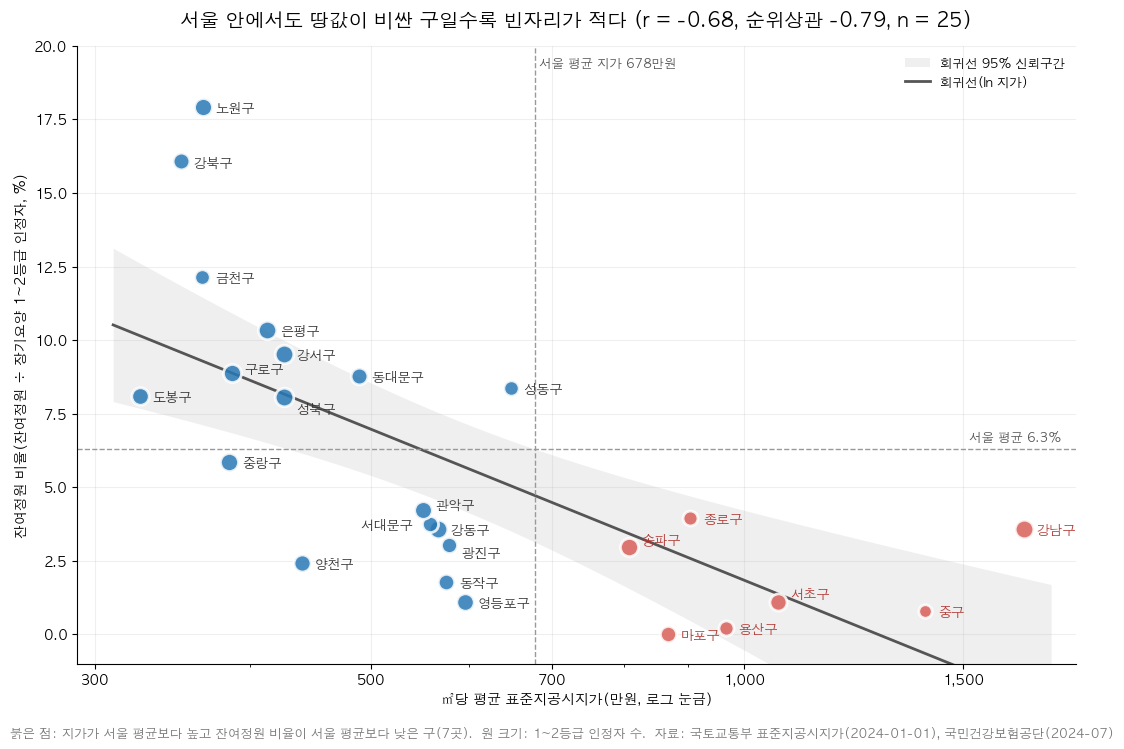

In [6]:
HIGHLIGHT = "#D95F59"
BASE = "#2878B5"
LABEL_OFFSET = {
    "서대문구": (-50, -4), "강동구": (9, -4), "관악구": (9, 0), "광진구": (9, -9),
    "서초구": (9, 3), "송파구": (9, 2), "성북구": (9, -12), "구로구": (9, 0),
}
from matplotlib.ticker import NullFormatter

gu["비싸고_빠듯함"] = (gu["평균_지가"] > seoul_land) & (gu["잔여정원_비율"] < seoul_vacancy_ratio)

x_grid = np.linspace(gu["ln_평균_지가"].min() - 0.05, gu["ln_평균_지가"].max() + 0.05, 200)
ols = smf.ols("잔여정원_비율 ~ ln_평균_지가", data=gu).fit()
band = ols.get_prediction(pd.DataFrame({"ln_평균_지가": x_grid})).summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(11, 7.5))
ax.fill_between(np.exp(x_grid) / 1e4, band["mean_ci_lower"], band["mean_ci_upper"],
                color="#999999", alpha=0.15, linewidth=0, label="회귀선 95% 신뢰구간")
ax.plot(np.exp(x_grid) / 1e4, band["mean"], color="#555555", linewidth=2, label="회귀선(ln 지가)")
ax.axvline(seoul_land / 1e4, color="#999999", linestyle="--", linewidth=1)
ax.axhline(seoul_vacancy_ratio, color="#999999", linestyle="--", linewidth=1)
for _, row in gu.iterrows():
    hot = row["비싸고_빠듯함"]
    ax.scatter(row["평균_지가"] / 1e4, row["잔여정원_비율"], s=30 + np.sqrt(row["중증_1_2등급"]) * 4,
               color=HIGHLIGHT if hot else BASE, alpha=0.85, edgecolor="white", linewidth=2, zorder=3)
    ax.annotate(row["자치구"], (row["평균_지가"] / 1e4, row["잔여정원_비율"]),
                xytext=LABEL_OFFSET.get(row["자치구"], (9, -4)), textcoords="offset points",
                fontsize=9.5, color="#B03A35" if hot else "#333333")
ax.text(seoul_land / 1e4, 19.6, f" 서울 평균 지가 {seoul_land / 1e4:,.0f}만원", fontsize=9, color="#555555", va="top")
ax.text(1800, seoul_vacancy_ratio + 0.25, f"서울 평균 {seoul_vacancy_ratio:.1f}%", fontsize=9, color="#555555", ha="right")
ax.set_xscale("log")
ax.set_xticks([300, 500, 700, 1000, 1500])
ax.set_xticklabels(["300", "500", "700", "1,000", "1,500"])
ax.set_xlim(290, 1850)
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_ylim(-1, 20)
ax.set_xlabel("㎡당 평균 표준지공시지가(만원, 로그 눈금)")
ax.set_ylabel("잔여정원 비율(잔여정원 ÷ 장기요양 1~2등급 인정자, %)")
ax.grid(alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper right", frameon=False, fontsize=9)
ax.set_title(
    f"서울 안에서도 땅값이 비싼 구일수록 빈자리가 적다 (r = {main['피어슨_r']:.2f}, 순위상관 {main['스피어만_rho']:.2f}, n = 25)",
    fontsize=14, pad=14,
)
fig.text(0.01, 0.01,
         f"붉은 점: 지가가 서울 평균보다 높고 잔여정원 비율이 서울 평균보다 낮은 구({gu['비싸고_빠듯함'].sum()}곳).  "
         "원 크기: 1~2등급 인정자 수.  자료: 국토교통부 표준지공시지가(2024-01-01), 국민건강보험공단(2024-07)",
         fontsize=9, color="#777777")
plt.tight_layout(rect=[0, 0.03, 1, 1])
fig.savefig(OUTPUT_DIR / "자치구별_지가_잔여정원_산점도.png", dpi=200, bbox_inches="tight")
plt.show()

### 7. 시각화: 빈자리가 적은 이유 — 정원이 적고, 있는 자리는 차 있다

잔여정원 비율은 `중증 수요 대비 정원 × (1 − 가동률)`로 분해된다. 지가가 높은 자치구의 빈자리가 적은 것이 (가) 애초에 정원이 적어서인지, (나) 있는 자리가 꽉 차서인지 두 축을 나누어 본다.

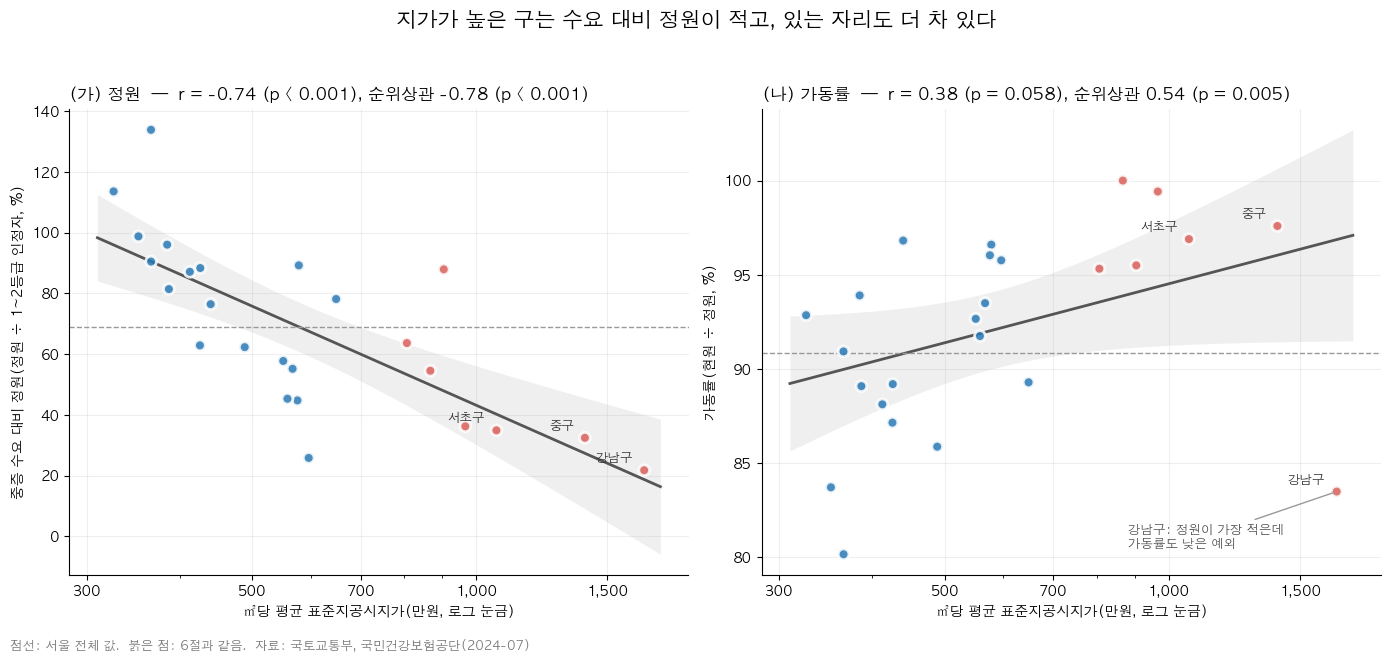

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharex=True)
panels = [
    ("중증_대비_정원", "중증 수요 대비 정원(정원 ÷ 1~2등급 인정자, %)", seoul_bed_ratio, "(가) 정원"),
    ("가동률", "가동률(현원 ÷ 정원, %)", seoul_occupancy, "(나) 가동률"),
]
for ax, (col, ylabel, seoul_value, title) in zip(axes, panels):
    stat = result.loc[[k for k, v in TARGETS.items() if v == col][0]]
    fit = smf.ols(f"{col} ~ ln_평균_지가", data=gu).fit()
    pred = fit.get_prediction(pd.DataFrame({"ln_평균_지가": x_grid})).summary_frame(alpha=0.05)
    ax.fill_between(np.exp(x_grid) / 1e4, pred["mean_ci_lower"], pred["mean_ci_upper"],
                    color="#999999", alpha=0.15, linewidth=0)
    ax.plot(np.exp(x_grid) / 1e4, pred["mean"], color="#555555", linewidth=2)
    ax.axhline(seoul_value, color="#999999", linestyle="--", linewidth=1)
    ax.scatter(gu["평균_지가"] / 1e4, gu[col], s=60,
               color=np.where(gu["비싸고_빠듯함"], HIGHLIGHT, BASE), alpha=0.85,
               edgecolor="white", linewidth=2, zorder=3)
    for _, row in gu.nlargest(3, "평균_지가").iterrows():
        ax.annotate(row["자치구"], (row["평균_지가"] / 1e4, row[col]), xytext=(-8, 6),
                    textcoords="offset points", ha="right", fontsize=9, color="#333333")
    p_text = lambda p: "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
    ax.set_title(f"{title}  —  r = {stat['피어슨_r']:.2f} ({p_text(stat['피어슨_p'])}), "
                 f"순위상관 {stat['스피어만_rho']:.2f} ({p_text(stat['스피어만_p'])})", fontsize=12, loc="left")
    ax.set_ylabel(ylabel)
    ax.set_xscale("log")
    ax.set_xticks([300, 500, 700, 1000, 1500])
    ax.set_xticklabels(["300", "500", "700", "1,000", "1,500"])
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel("㎡당 평균 표준지공시지가(만원, 로그 눈금)")
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
axes[1].annotate("강남구: 정원이 가장 적은데\n가동률도 낮은 예외",
                 (gu.set_index("자치구").loc["강남구", "평균_지가"] / 1e4, gu.set_index("자치구").loc["강남구", "가동률"]),
                 xytext=(-150, -40), textcoords="offset points", fontsize=9, color="#555555",
                 arrowprops=dict(arrowstyle="-", color="#999999"))
fig.suptitle("지가가 높은 구는 수요 대비 정원이 적고, 있는 자리도 더 차 있다", fontsize=15, y=0.99)
fig.text(0.01, 0.005, "점선: 서울 전체 값.  붉은 점: 6절과 같음.  자료: 국토교통부, 국민건강보험공단(2024-07)",
         fontsize=9, color="#777777")
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
fig.savefig(OUTPUT_DIR / "자치구별_지가_정원_가동률.png", dpi=200, bbox_inches="tight")
plt.show()

### 8. 강건성 점검

다음을 바꿔 가며 상관이 유지되는지 본다.

- 지가 지표: 평균 / 중위 / 대지 평균
- 표본: 25개 구 전체 / 가동률이 낮은 예외인 강남구 제외 / 지가 상위 3개 구(강남·중·서초) 제외
- 한 구씩 빼고 다시 계산(leave-one-out)

In [8]:
top3 = gu.nlargest(3, "평균_지가")["자치구"].tolist()
samples = {
    "25개 구": gu,
    "강남구 제외(24)": gu.loc[gu["자치구"].ne("강남구")],
    "지가 상위 3개 구 제외(22)": gu.loc[~gu["자치구"].isin(top3)],
}
measures = {"평균 지가": "ln_평균_지가", "중위 지가": "ln_중위_지가", "대지 평균 지가": "ln_대지_평균_지가"}

robust = pd.DataFrame([
    {"표본": s_name, "지가 지표": m_name, **correlate(data, "잔여정원_비율", x=m_col)}
    for s_name, data in samples.items() for m_name, m_col in measures.items()
])
robust.to_csv(OUTPUT_DIR / "자치구별_강건성.csv", index=False, encoding="utf-8-sig")

loo = pd.DataFrame([
    {"제외 자치구": name, **correlate(gu.loc[gu["자치구"].ne(name)], "잔여정원_비율")}
    for name in gu["자치구"]
])

display(
    robust[["표본", "지가 지표", "n", "피어슨_r", "피어슨_p", "스피어만_rho", "스피어만_p", "지가10%당_변화(%p)"]]
    .style.format({"n": "{:.0f}", "피어슨_r": "{:.2f}", "피어슨_p": "{:.4f}", "스피어만_rho": "{:.2f}",
                   "스피어만_p": "{:.4f}", "지가10%당_변화(%p)": "{:.2f}"})
    .hide(axis="index")
)
display(Markdown(
    f"- 지가 상위 3개 구: {'·'.join(top3)}\n"
    f"- 한 구씩 빼고 다시 계산한 피어슨 r의 범위: **{loo['피어슨_r'].min():.2f} ~ {loo['피어슨_r'].max():.2f}**, "
    f"모든 경우 p < {loo['피어슨_p'].max():.4f}"
))

표본,지가 지표,n,피어슨_r,피어슨_p,스피어만_rho,스피어만_p,지가10%당_변화(%p)
25개 구,평균 지가,25,-0.68,0.0002,-0.79,0.0000,-0.71
25개 구,중위 지가,25,-0.69,0.0001,-0.79,0.0000,-0.83
25개 구,대지 평균 지가,25,-0.67,0.0003,-0.75,0.0000,-0.69
강남구 제외(24),평균 지가,24,-0.74,0.0000,-0.81,0.0000,-0.87
강남구 제외(24),중위 지가,24,-0.75,0.0000,-0.81,0.0000,-1.04
강남구 제외(24),대지 평균 지가,24,-0.72,0.0001,-0.78,0.0000,-0.85
지가 상위 3개 구 제외(22),평균 지가,22,-0.73,0.0001,-0.76,0.0000,-1.04
지가 상위 3개 구 제외(22),중위 지가,22,-0.73,0.0001,-0.76,0.0000,-1.17
지가 상위 3개 구 제외(22),대지 평균 지가,22,-0.72,0.0002,-0.72,0.0002,-1.06


- 지가 상위 3개 구: 강남구·중구·서초구
- 한 구씩 빼고 다시 계산한 피어슨 r의 범위: **-0.74 ~ -0.66**, 모든 경우 p < 0.0004

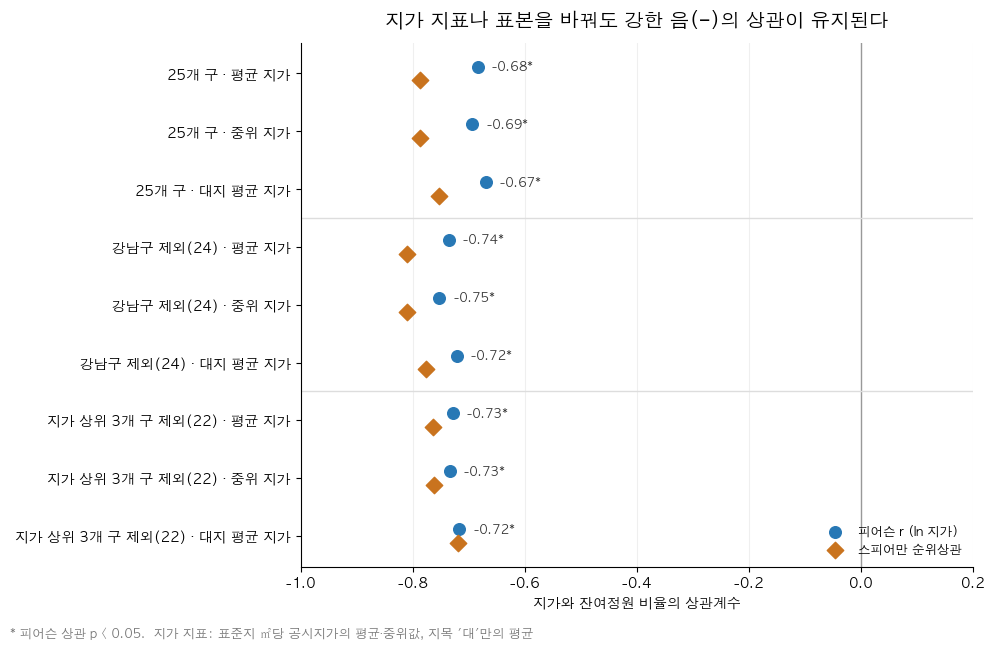

In [9]:
plot = robust.copy()
plot["label"] = plot["표본"] + " · " + plot["지가 지표"]
plot = plot.iloc[::-1].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 6.5))
y = np.arange(len(plot))
ax.axvline(0, color="#999999", linewidth=1)
ax.scatter(plot["피어슨_r"], y + 0.12, s=70, color=BASE, zorder=3, label="피어슨 r (ln 지가)")
ax.scatter(plot["스피어만_rho"], y - 0.12, s=70, color="#C9731E", marker="D", zorder=3, label="스피어만 순위상관")
for i, row in plot.iterrows():
    ax.annotate(f"{row['피어슨_r']:.2f}{'*' if row['피어슨_p'] < 0.05 else ''}", (row["피어슨_r"], i + 0.12),
                xytext=(10, 0), textcoords="offset points", ha="left", va="center", fontsize=9, color="#333333")
ax.set_yticks(y)
ax.set_yticklabels(plot["label"])
for boundary in (2.5, 5.5):
    ax.axhline(boundary, color="#DDDDDD", linewidth=1)
ax.set_xlim(-1, 0.2)
ax.set_xlabel("지가와 잔여정원 비율의 상관계수")
ax.grid(axis="x", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.set_title("지가 지표나 표본을 바꿔도 강한 음(−)의 상관이 유지된다", fontsize=14, pad=12)
fig.text(0.01, 0.01, "* 피어슨 상관 p < 0.05.  지가 지표: 표준지 ㎡당 공시지가의 평균·중위값, 지목 '대'만의 평균",
         fontsize=9, color="#777777")
plt.tight_layout(rect=[0, 0.03, 1, 1])
fig.savefig(OUTPUT_DIR / "자치구별_강건성.png", dpi=200, bbox_inches="tight")
plt.show()

### 9. 해석

In [10]:
by_gu = gu.set_index("자치구")
hot = gu.loc[gu["비싸고_빠듯함"]].sort_values("평균_지가", ascending=False)
cheap5 = gu.nsmallest(5, "평균_지가")
rich5 = gu.nlargest(5, "평균_지가")
bed = result.loc["중증 수요 대비 정원(%)"]
occ = result.loc["가동률(%)"]
no_gangnam = robust.set_index(["표본", "지가 지표"]).loc[("강남구 제외(24)", "평균 지가")]

display(Markdown(f"""
- 서울 25개 자치구에서 ln(평균 지가)와 잔여정원 비율의 피어슨 상관은 **{main['피어슨_r']:.2f}**(p = {main['피어슨_p']:.4f}), 스피어만 순위상관은 **{main['스피어만_rho']:.2f}**다. 지가가 10% 높은 자치구는 잔여정원 비율이 평균 약 {abs(main['지가10%당_변화(%p)']):.1f}%p 낮다. 시도 비교와 달리 극단값 하나에 기대지 않고, 지가 지표·표본을 바꿔도(8절) 상관은 −0.6 ~ −0.8 범위에서 모두 유의하다.
- 지가 하위 5개 구({'·'.join(cheap5['자치구'])})의 잔여정원 비율은 평균 {cheap5['잔여정원_비율'].mean():.1f}%인 반면, 지가 상위 5개 구({'·'.join(rich5['자치구'])})는 {rich5['잔여정원_비율'].mean():.1f}%다.
- 지가가 서울 평균보다 높고 빈자리는 서울 평균보다 적은 구는 {len(hot)}곳({'·'.join(hot['자치구'])})이다. 이 중 마포·용산·중구·서초구에 남은 자리는 각각 {by_gu.loc['마포구', '잔여정원']:.0f}·{by_gu.loc['용산구', '잔여정원']:.0f}·{by_gu.loc['중구', '잔여정원']:.0f}·{by_gu.loc['서초구', '잔여정원']:.0f}석이다.
- 빈자리가 적은 이유는 두 갈래로 확인된다(7절). (가) 지가가 높은 구는 중증 수요 대비 정원 자체가 적고(r = {bed['피어슨_r']:.2f}), (나) 있는 자리의 가동률은 더 높다(순위상관 {occ['스피어만_rho']:.2f}). 땅값이 비싼 곳에는 시설이 덜 들어서고, 들어선 시설은 차 있다는 한국은행의 진입 비용 논리와 같은 방향이다.
- 강남구는 지가가 가장 높고 수요 대비 정원은 {by_gu.loc['강남구', '중증_대비_정원']:.1f}%로 가장 적지만, 가동률이 {by_gu.loc['강남구', '가동률']:.1f}%로 낮아 잔여정원 비율({by_gu.loc['강남구', '잔여정원_비율']:.1f}%)은 중위권이다. 강남구를 빼면 상관은 r = {no_gangnam['피어슨_r']:.2f}로 오히려 강해진다.
"""))


- 서울 25개 자치구에서 ln(평균 지가)와 잔여정원 비율의 피어슨 상관은 **-0.68**(p = 0.0002), 스피어만 순위상관은 **-0.79**다. 지가가 10% 높은 자치구는 잔여정원 비율이 평균 약 0.7%p 낮다. 시도 비교와 달리 극단값 하나에 기대지 않고, 지가 지표·표본을 바꿔도(8절) 상관은 −0.6 ~ −0.8 범위에서 모두 유의하다.
- 지가 하위 5개 구(도봉구·강북구·금천구·노원구·중랑구)의 잔여정원 비율은 평균 12.0%인 반면, 지가 상위 5개 구(강남구·중구·서초구·용산구·종로구)는 1.9%다.
- 지가가 서울 평균보다 높고 빈자리는 서울 평균보다 적은 구는 7곳(강남구·중구·서초구·용산구·종로구·마포구·송파구)이다. 이 중 마포·용산·중구·서초구에 남은 자리는 각각 0·1·2·10석이다.
- 빈자리가 적은 이유는 두 갈래로 확인된다(7절). (가) 지가가 높은 구는 중증 수요 대비 정원 자체가 적고(r = -0.74), (나) 있는 자리의 가동률은 더 높다(순위상관 0.54). 땅값이 비싼 곳에는 시설이 덜 들어서고, 들어선 시설은 차 있다는 한국은행의 진입 비용 논리와 같은 방향이다.
- 강남구는 지가가 가장 높고 수요 대비 정원은 21.7%로 가장 적지만, 가동률이 83.5%로 낮아 잔여정원 비율(3.6%)은 중위권이다. 강남구를 빼면 상관은 r = -0.74로 오히려 강해진다.


### 해석상 주의

- **상관이지 인과가 아니다.** 지가가 높은 구는 도심·업무지구라 주거 인구 구성, 소득, 대체 시설(요양병원), 가족 돌봄 여건도 다르다. 한국은행의 −22.8(지가 10%당 −2.3%p)은 고정효과·통제변수를 넣은 시군구 패널모형의 계수라서, 본 분석의 단순 횡단면 기울기와 크기를 직접 견줄 수 없다. 본 분석은 같은 방향의 관계가 서울 안에서도 뚜렷하다는 것을 보여준다.
- **잔여정원 규모가 작다.** 자치구별 잔여정원은 0~207석이라 몇 명의 입·퇴소로 비율이 바뀔 수 있다. 그래서 순위상관을 함께 보고, 공급량 자체(중증 수요 대비 정원)에서도 같은 방향을 확인했다.
- **시설 소재지 기준이다.** 입소자는 다른 구의 시설을 이용할 수 있으므로, 이 지표는 해당 구 안의 공급 여유를 뜻하지 거주자의 실제 접근성을 뜻하지 않는다(행정동 E2SFCA 분석 참고).
- 잔여정원 비율의 분모(1~2등급 인정자)는 한국은행 시군구 분석의 대리지표이며, 생애말기 고령인구와 수준이 다르다.

In [11]:
# 핵심 수치 검증
assert gu.iloc[0]["자치구"] == "강남구" and gu.iloc[-1]["자치구"] == "도봉구"
assert round(seoul_vacancy_ratio, 1) == 6.3
assert round(main["피어슨_r"], 2) == -0.68 and main["피어슨_p"] < 0.001
assert round(main["스피어만_rho"], 2) == -0.79
assert round(bed["피어슨_r"], 2) == -0.74
assert round(occ["스피어만_rho"], 2) == 0.54
assert (robust["피어슨_p"] < 0.05).all() and (robust["스피어만_p"] < 0.05).all()
assert (loo["피어슨_p"] < 0.05).all()
print("검증 통과")

검증 통과


### 출처

- 국토교통부_표준지공시지가(2024-01-01): https://www.data.go.kr/data/15004246/fileData.do (이력 파일 `국토교통부_표준지공시지가_20240101`)
- 국민건강보험공단_장기요양기관 시설별 현황: https://www.data.go.kr/data/15124763/fileData.do
- 국민건강보험공단_노인장기요양보험 등급판정 현황: https://www.data.go.kr/data/3051421/fileData.do
- 한국은행 이슈노트 [제2026-5호] 초고령사회와 생애말기 필수산업의 활성화 (그림 3.2, 별첨 2)